# Preparação do Dataset
Gerador de um dataset de textos sintéticos. No seminário foi definido vetores de 384 dimensões (modelo multilingual-e5-small) e documentos textuais em larga escala.

In [1]:
import json, random, pathlib

# Configuração do dataset
NUM_DOCS = 2000       # ajuste se precisar (mínimo 1000 para experimentos)
CHUNK_SIZE = 200      # palavras por chunk
OUTPUT_FILE = "dataset.jsonl"

# Frases base para variação sintética
TEMPLATES = [
    "O processamento distribuído permite escalar cargas de trabalho de IA",
    "Ray Data organiza datasets em blocks armazenados no object store",
    "O modelo multilingual-e5-small gera vetores de 384 dimensões",
    "Embeddings são representações vetoriais densas de textos e documentos",
    "O particionamento de dados melhora o throughput em pipelines RAG",
    "Sistemas distribuídos exigem balanceamento de carga entre workers",
    "A busca vetorial aproximada permite recuperação eficiente de documentos",
    "O overhead de comunicação limita o ganho linear com mais workers",
]

def make_chunk(idx):
    words = []
    for _ in range(CHUNK_SIZE):
        base = random.choice(TEMPLATES)
        words.append(base)
    return {"id": idx, "text": " ".join(words)}

with open(OUTPUT_FILE, "w", encoding="utf-8") as f:
    for i in range(NUM_DOCS):
        f.write(json.dumps(make_chunk(i), ensure_ascii=False) + "\n")

print(f"Dataset gerado: {NUM_DOCS} chunks → {OUTPUT_FILE}")

Dataset gerado: 2000 chunks → dataset.jsonl


# Pipeline Base (Baseline Funcional)

Antes dos experimentos paramétricos, temos que confirmar que o pipeline completo funciona end-to-end. Este é o baseline definido no seminário.

In [2]:
!pip install --upgrade pip

In [3]:
!pip install "ray[data]"

  Using cached ray-2.59.0-cp311-cp311-win_amd64.whl.metadata (23 kB)
  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata (6.6 kB)
  Using cached pandas-3.0.6-cp311-cp311-win_amd64.whl.metadata (19 kB)
  Using cached pyarrow-26.0.0-cp311-cp311-win_amd64.whl.metadata (3.0 kB)
Using cached ray-2.59.0-cp311-cp311-win_amd64.whl (29.1 MB)
Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl (12.6 MB)
Using cached pandas-3.0.6-cp311-cp311-win_amd64.whl (9.9 MB)
Using cached pyarrow-26.0.0-cp311-cp311-win_amd64.whl (28.5 MB)

   ---------------------------------------- 0/4 [pyarrow]
   ---------------------------------------- 0/4 [pyarrow]
   ---------------------------------------- 0/4 [pyarrow]
   ---------------------------------------- 0/4 [pyarrow]
   ---------------------------------------- 0/4 [pyarrow]
   ---------------------------------------- 0/4 [pyarrow]
   ---------------------------------------- 0/4 [pyarrow]
   ---------------------------------------- 0/4 [pyarrow]
   -

In [4]:
!pip install sentence-transformers transformers torch

In [5]:
!pip install pandas numpy matplotlib psutil

In [6]:
!pip install cassandra-driver

In [7]:
import os
os.environ["RAY_enable_windows_or_macos_cluster"] = "0"


import ray
import time
import psutil

# Encerra uma eventual sessão anterior
ray.shutdown()

# Inicializa Ray localmente (multiprocessamento)
ray.init(
    ignore_reinit_error=True,
    include_dashboard=False,
    num_cpus=2,
    configure_logging=False,
    _system_config={"enable_worker_prestart": False}
)
print(f"Ray inicializado | CPUs: {ray.available_resources().get('CPU', 0):.0f}")

# --- Classe do modelo de embedding ---
class EmbeddingModel:
    def __init__(self):
        from sentence_transformers import SentenceTransformer
        self.model = SentenceTransformer("intfloat/multilingual-e5-small")

    def __call__(self, batch: dict) -> dict:
        texts = batch["text"]
        embeddings = self.model.encode(
            texts.tolist(),
            batch_size=64,      # batch_size interno ao modelo
            show_progress_bar=False
        )
        batch["embedding"] = embeddings
        return batch

# --- Leitura do dataset ---
start = time.time()
ds = ray.data.read_json("dataset.jsonl").materialize() 
print(f"Dataset carregado | Blocos: {ds.num_blocks()} | Registros: {ds.count()}")

# --- Aplicação do modelo com map_batches() ---
ds_emb = ds.map_batches(
    EmbeddingModel,
    batch_size=64,
    concurrency=2,       # número de workers Ray
    batch_format="numpy"
)

# Força a materialização (execução real)
result = ds_emb.take_all()
elapsed = time.time() - start

total = len(result)
throughput = total / elapsed
print(f"\n=== BASELINE ===")
print(f"Total embeddings : {total}")
print(f"Tempo total (s)  : {elapsed:.2f}")
print(f"Throughput       : {throughput:.1f} emb/s")
print(f"Memória RAM usada: {psutil.virtual_memory().percent:.1f}%")

ray.shutdown()

c:\Git\ray-embedding-experiments\.venv-ray-test\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-15 09:30:58,920	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html


Ray inicializado | CPUs: 2


2026-10-15 09:31:23,327	INFO streaming_executor.py:214 -- Starting execution of Dataset dataset_034gLLJayLWKGblFsBMp49_0. Full logs are in C:\Users\lucas\AppData\Local\Temp\ray\session_2026-10-15_09-30-59_596606_35484\logs\ray-data
2026-10-15 09:31:23,328	INFO streaming_executor.py:215 -- Execution plan of Dataset dataset_034gLLJayLWKGblFsBMp49_0: InputDataBuffer[Input] -> TaskPoolMapOperator[ReadArrowJSON]
2026-10-15 09:31:23,340	INFO __init__.py:56 -- Progress will be logged because stdout is a non-interactive terminal.
2026-10-15 09:31:23,404	INFO logging_progress.py:174 -- ======= Running Dataset: dataset_034gLLJayLWKGblFsBMp49_0 =======
2026-10-15 09:31:23,406	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-15 09:31:23,407	INFO logging_progress.py:227 -- Active & requested resources: 0/0 CPU, 0.0B/0.0B object store
2026-10-15 09:31:23,407	INFO logging_progress.py:181 -- 
2026-10-15 09:31:23,408	INFO logging_progress.py:231 -- ReadArrowJSON->SplitBlocks(25): 0/1
2026-10

Dataset carregado | Blocos: 25 | Registros: 2000


2026-10-15 09:31:25,075	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-15 09:31:25,076	INFO logging_progress.py:227 -- Active & requested resources: 0/0 CPU, 0.0B/0.0B object store (pending: 2 CPU)
2026-10-15 09:31:25,077	INFO logging_progress.py:181 -- 
2026-10-15 09:31:25,077	INFO logging_progress.py:231 -- MapBatches(EmbeddingModel): 0/1
2026-10-15 09:31:25,078	INFO logging_progress.py:233 --   Tasks: 0; Actors: 2 (running=0, restarting=0, pending=2, active=0, idle=0, util=0.000, tasks_in_flight=0); Queued blocks: 25 (0.0B); Resources: 0.0 CPU, 0.0B object store; [all objects local]
2026-10-15 09:31:25,079	INFO logging_progress.py:192 -- =================================================================
2026-10-15 09:31:35,110	INFO logging_progress.py:174 -- ======= Running Dataset: dataset_034gLLP2lyQX69mv4g2ZuL_0 =======
2026-10-15 09:31:35,110	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-15 09:31:35,111	INFO logging_progress.py:227 -- Active & requested


=== BASELINE ===
Total embeddings : 2000
Tempo total (s)  : 565.54
Throughput       : 3.5 emb/s
Memória RAM usada: 85.8%


# Experimento 1 — Particionamento (QP1)

Variável: número de blocos → valores testados: 4, 8, 16, 32
Fixos: batch_size = 64, workers (concurrency) = 2

In [8]:
import ray, time, psutil, json

BLOCKS_VALUES = [4, 8, 16, 32]   # QP1 — variável
BATCH_SIZE    = 64                   # fixo
CONCURRENCY   = 2                    # fixo
N_RUNS        = 5                    # 5 repetições por configuração
RESULTS_FILE  = "results_exp1.jsonl"

class EmbeddingModel:
    def __init__(self):
        from sentence_transformers import SentenceTransformer
        self.model = SentenceTransformer("intfloat/multilingual-e5-small")
    def __call__(self, batch):
        batch["embedding"] = self.model.encode(
            batch["text"].tolist(), batch_size=BATCH_SIZE, show_progress_bar=False)
        return batch

ray.init(ignore_reinit_error=True)

with open(RESULTS_FILE, "w") as out:
    for n_blocks in BLOCKS_VALUES:
        times = []
        for run in range(N_RUNS):
            ds = ray.data.read_json("dataset.jsonl").repartition(n_blocks)
            t0 = time.time()
            result = ds.map_batches(
                EmbeddingModel, batch_size=BATCH_SIZE,
                concurrency=CONCURRENCY, batch_format="numpy"
            ).take_all()
            elapsed = time.time() - t0
            times.append(elapsed)
            print(f"  blocks={n_blocks} run={run+1}/{N_RUNS}: {elapsed:.2f}s")

        import statistics
        rec = {
            "experiment": "exp1_particionamento",
            "n_blocks": n_blocks, "batch_size": BATCH_SIZE, "concurrency": CONCURRENCY,
            "mean_time_s": statistics.mean(times),
            "std_time_s": statistics.stdev(times) if len(times) > 1 else 0,
            "throughput_emb_s": len(result) / statistics.mean(times),
            "memory_pct": psutil.virtual_memory().percent,
        }
        out.write(json.dumps(rec) + "\n")
        print(f"[EXP1] blocks={n_blocks} | média={rec['mean_time_s']:.2f}s ± {rec['std_time_s']:.2f}")

ray.shutdown()
print(f"\nResultados salvos em: {RESULTS_FILE}")

2026-10-15 09:40:36,866	WARNING util.py:650 -- The argument ``concurrency`` is deprecated in Ray 2.51. Please specify argument ``compute`` instead. For more information, see https://docs.ray.io/en/master/data/transforming-data.html#stateful-transforms.
2026-10-15 09:40:36,876	INFO streaming_executor.py:214 -- Starting execution of Dataset dataset_034gLZOqWQesbazE3KB7Hw_0. Full logs are in C:\Users\lucas\AppData\Local\Temp\ray\session_2026-10-15_09-40-32_537309_35484\logs\ray-data
2026-10-15 09:40:36,877	INFO streaming_executor.py:215 -- Execution plan of Dataset dataset_034gLZOqWQesbazE3KB7Hw_0: InputDataBuffer[Input] -> TaskPoolMapOperator[ReadArrowJSON] -> AllToAllOperator[Repartition] -> ActorPoolMapOperator[MapBatches(EmbeddingModel)]
2026-10-15 09:40:37,105	INFO logging_progress.py:174 -- ======= Running Dataset: dataset_034gLZOqWQesbazE3KB7Hw_0 =======
2026-10-15 09:40:37,107	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-15 09:40:37,108	INFO logging_progress.py:227 

  blocks=4 run=1/5: 394.52s


2026-10-15 09:47:11,572	INFO logging_progress.py:192 -- =================================================================
2026-10-15 09:47:21,633	INFO logging_progress.py:174 -- ======= Running Dataset: dataset_034gLjP9f2pn0gLstLaa9H_0 =======
2026-10-15 09:47:21,634	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-15 09:47:21,634	INFO logging_progress.py:227 -- Active & requested resources: 0/20 CPU, 25.9MiB/511.6MiB object store (pending: 2 CPU)
2026-10-15 09:47:21,635	INFO logging_progress.py:181 -- 
2026-10-15 09:47:21,635	INFO logging_progress.py:231 -- ReadArrowJSON->SplitBlocks(40): 2000/2000
2026-10-15 09:47:21,636	INFO logging_progress.py:233 --   Tasks: 0; Actors: 0; Queued blocks: 0 (0.0B); Resources: 0.0 CPU, 0.0B object store
2026-10-15 09:47:21,636	INFO logging_progress.py:231 -- Repartition: 2000/2000
2026-10-15 09:47:21,637	INFO logging_progress.py:233 --   Tasks: 0; Actors: 0; Queued blocks: 0 (0.0B); Resources: 0.0 CPU, 25.9MiB object store; 2000 rows outpu

  blocks=4 run=2/5: 386.72s


2026-10-15 09:53:48,330	INFO logging_progress.py:174 -- ======= Running Dataset: dataset_034gLtDCGQpZyoxaxXugOt_0 =======
2026-10-15 09:53:48,331	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-15 09:53:48,332	INFO logging_progress.py:227 -- Active & requested resources: 0/20 CPU, 25.9MiB/511.6MiB object store (pending: 2 CPU)
2026-10-15 09:53:48,332	INFO logging_progress.py:181 -- 
2026-10-15 09:53:48,333	INFO logging_progress.py:231 -- ReadArrowJSON->SplitBlocks(40): 2000/2000
2026-10-15 09:53:48,333	INFO logging_progress.py:233 --   Tasks: 0; Actors: 0; Queued blocks: 0 (0.0B); Resources: 0.0 CPU, 0.0B object store
2026-10-15 09:53:48,333	INFO logging_progress.py:231 -- Repartition: 2000/2000
2026-10-15 09:53:48,334	INFO logging_progress.py:233 --   Tasks: 0; Actors: 0; Queued blocks: 0 (0.0B); Resources: 0.0 CPU, 25.9MiB object store; 2000 rows output
2026-10-15 09:53:48,334	INFO logging_progress.py:231 --     - Split Repartition: 2000/1
2026-10-15 09:53:48,335	INFO log

...

  blocks=32 run=3/5: 292.53s


2026-10-15 11:17:06,949	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-15 11:17:06,950	INFO logging_progress.py:227 -- Active & requested resources: 0/0 CPU, 0.0B/0.0B object store (pending: 2 CPU)
2026-10-15 11:17:06,951	INFO logging_progress.py:181 -- 
2026-10-15 11:17:06,951	INFO logging_progress.py:231 -- ReadArrowJSON->SplitBlocks(40): 0/1
2026-10-15 11:17:06,951	INFO logging_progress.py:233 --   Tasks: 1 [backpressured:tasks(ResourceBudget)]; Actors: 0; Queued blocks: 0 (0.0B); Resources: 1.0 CPU, 0.0B object store
2026-10-15 11:17:06,952	INFO logging_progress.py:231 -- Repartition: 0/1
2026-10-15 11:17:06,953	INFO logging_progress.py:233 --   Tasks: 0; Actors: 0; Queued blocks: 0 (0.0B); Resources: 0.0 CPU, 0.0B object store; 0 rows output
2026-10-15 11:17:06,954	INFO logging_progress.py:231 --     - Split Repartition: 0/1
2026-10-15 11:17:06,954	INFO logging_progress.py:231 -- MapBatches(EmbeddingModel): 0/1
2026-10-15 11:17:06,954	INFO logging_progress.py:233 --  

  blocks=32 run=4/5: 292.66s


(raylet)   File "c:\Git\ray-embedding-experiments\.venv-ray-test\Lib\site-packages\ray\_private\worker.py", line 2825 in disconnectWindows fatal exception: 
(raylet)   File access violation"c:\Git\ray-embedding-experiments\.venv-ray-test\Lib\site-packages\ray\_private\worker.py", line 629 in job_logging_config
(raylet) 
(raylet) 
(raylet)   File "  File "c:\Git\ray-embedding-experiments\.venv-ray-test\Lib\site-packages\ray\_private\worker.py", line 2127 in shutdown
(raylet) c:\Git\ray-embedding-experiments\.venv-ray-test\Lib\site-packages\ray\_private\client_mode_hook.py", line 134 in wrapper
(raylet)   File "c:\Git\ray-embedding-experiments\.venv-ray-test\Lib\site-packages\ray\_private\worker.py"Windows fatal exception: access violation
(raylet) 
(raylet) , line 1173 in wrapper
(raylet)   File "Windows fatal exception: access violation
(raylet) 
(raylet)   File c:\Git\ray-embedding-experiments\.venv-ray-test\Lib\site-packages\ray\_private\worker.py", line 2196 in _should_ignore_worker

  blocks=32 run=5/5: 292.81s
[EXP1] blocks=32 | média=292.96s ± 0.57

Resultados salvos em: results_exp1.jsonl


# Experimento 2 — Batch Size (QP2)

Variável: batch_size → valores: 32, 64, 128, 256
Fixos: n_blocks = 8, concurrency = 2

In [9]:
import ray, time, psutil, json, statistics

BATCH_SIZES = [32, 64, 128, 256]   # QP2 — variável
N_BLOCKS    = 8                       # fixo
CONCURRENCY = 2                       # fixo
N_RUNS      = 5
RESULTS_FILE = "results_exp2.jsonl"

def make_model_class(batch_sz):
    class EmbeddingModel:
        def __init__(self):
            from sentence_transformers import SentenceTransformer
            self.model = SentenceTransformer("intfloat/multilingual-e5-small")
        def __call__(self, batch):
            mem_before = psutil.virtual_memory().used / (1024**2)
            batch["embedding"] = self.model.encode(
                batch["text"].tolist(), batch_size=batch_sz, show_progress_bar=False)
            mem_after = psutil.virtual_memory().used / (1024**2)
            batch["mem_delta_mb"] = [mem_after - mem_before] * len(batch["text"])
            return batch
    return EmbeddingModel

ray.init(ignore_reinit_error=True)

with open(RESULTS_FILE, "w") as out:
    for bs in BATCH_SIZES:
        times, mem_peaks = [], []
        for run in range(N_RUNS):
            ds = ray.data.read_json("dataset.jsonl").repartition(N_BLOCKS)
            t0 = time.time()
            result = ds.map_batches(
                make_model_class(bs), batch_size=bs,
                concurrency=CONCURRENCY, batch_format="numpy"
            ).take_all()
            elapsed = time.time() - t0
            times.append(elapsed)
            mem_peaks.append(psutil.virtual_memory().percent)
            print(f"  batch_size={bs} run={run+1}/{N_RUNS}: {elapsed:.2f}s | mem={mem_peaks[-1]:.1f}%")

        rec = {
            "experiment": "exp2_batching",
            "batch_size": bs, "n_blocks": N_BLOCKS, "concurrency": CONCURRENCY,
            "mean_time_s": statistics.mean(times),
            "std_time_s": statistics.stdev(times) if len(times) > 1 else 0,
            "throughput_emb_s": len(result) / statistics.mean(times),
            "mean_memory_pct": statistics.mean(mem_peaks),
        }
        out.write(json.dumps(rec) + "\n")
        print(f"[EXP2] bs={bs} | média={rec['mean_time_s']:.2f}s | throughput={rec['throughput_emb_s']:.1f} emb/s")

ray.shutdown()
print(f"\nResultados salvos em: {RESULTS_FILE}")

2026-10-15 11:26:58,886	WARNING util.py:650 -- The argument ``concurrency`` is deprecated in Ray 2.51. Please specify argument ``compute`` instead. For more information, see https://docs.ray.io/en/master/data/transforming-data.html#stateful-transforms.
2026-10-15 11:26:58,891	INFO streaming_executor.py:214 -- Starting execution of Dataset dataset_034gOBF2YDezypC0dyPNlp_0. Full logs are in C:\Users\lucas\AppData\Local\Temp\ray\session_2026-10-15_11-26-53_011101_35484\logs\ray-data
2026-10-15 11:26:58,892	INFO streaming_executor.py:215 -- Execution plan of Dataset dataset_034gOBF2YDezypC0dyPNlp_0: InputDataBuffer[Input] -> TaskPoolMapOperator[ReadArrowJSON] -> AllToAllOperator[Repartition] -> ActorPoolMapOperator[MapBatches(EmbeddingModel)]
2026-10-15 11:26:59,078	INFO logging_progress.py:174 -- ======= Running Dataset: dataset_034gOBF2YDezypC0dyPNlp_0 =======
2026-10-15 11:26:59,081	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-15 11:26:59,082	INFO logging_progress.py:227 

  batch_size=32 run=1/5: 288.72s | mem=87.5%


(MapWorker(MapBatches(EmbeddingModel)) pid=6312) Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads. [repeated 2x across cluster]
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2972.04it/s]
2026-10-15 11:31:57,801	INFO logging_progress.py:174 -- ======= Running Dataset: dataset_034gOIYzwmr9bHJJzGHKpw_0 =======
2026-10-15 11:31:57,801	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-15 11:31:57,802	INFO logging_progress.py:227 -- Active & requested resources: 0/20 CPU, 25.9MiB/945.6MiB object store (pending: 2 CPU)
2026-10-15 11:31:57,803	INFO logging_progress.py:181 -- 
2026-10-15 11:31:57,803	INFO logging_progress.py:231 -- ReadArrowJSON->SplitBlocks(40): 2000/2000
2026-10-15 11:31:57,803	INFO logging_progress.py:233 --   Tasks: 0; Actors: 0; Queued blocks: 0 (0.0B); Resources: 0.0 CPU, 0.0B object store
2026-10-15 11:31:57,804	INFO logging_progress.py:231 -- Repartition: 2000/200

  batch_size=32 run=2/5: 287.31s | mem=86.4%


(MapWorker(MapBatches(EmbeddingModel)) pid=42604) Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads. [repeated 2x across cluster]
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3154.80it/s]
2026-10-15 11:36:45,118	INFO logging_progress.py:174 -- ======= Running Dataset: dataset_034gOPqkKxXNaERFWdG3hR_0 =======
2026-10-15 11:36:45,119	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-15 11:36:45,120	INFO logging_progress.py:227 -- Active & requested resources: 0/20 CPU, 25.9MiB/945.6MiB object store (pending: 2 CPU)
2026-10-15 11:36:45,121	INFO logging_progress.py:181 -- 
2026-10-15 11:36:45,121	INFO logging_progress.py:231 -- ReadArrowJSON->SplitBlocks(40): 2000/2000
2026-10-15 11:36:45,121	INFO logging_progress.py:233 --   Tasks: 0; Actors: 0; Queued blocks: 0 (0.0B); Resources: 0.0 CPU, 0.0B object store
2026-10-15 11:36:45,122	INFO logging_progress.py:231 -- Repartition: 2000/20

...

  batch_size=256 run=3/5: 337.65s | mem=69.7%


2026-10-15 13:09:16,915	INFO logging_progress.py:227 -- Active & requested resources: 0/0 CPU, 0.0B/0.0B object store (pending: 2 CPU)
2026-10-15 13:09:16,916	INFO logging_progress.py:181 -- 
2026-10-15 13:09:16,917	INFO logging_progress.py:231 -- ReadArrowJSON->SplitBlocks(40): 0/1
2026-10-15 13:09:16,918	INFO logging_progress.py:233 --   Tasks: 1 [backpressured:tasks(ResourceBudget)]; Actors: 0; Queued blocks: 0 (0.0B); Resources: 1.0 CPU, 0.0B object store
2026-10-15 13:09:16,919	INFO logging_progress.py:231 -- Repartition: 0/1
2026-10-15 13:09:16,920	INFO logging_progress.py:233 --   Tasks: 0; Actors: 0; Queued blocks: 0 (0.0B); Resources: 0.0 CPU, 0.0B object store; 0 rows output
2026-10-15 13:09:16,921	INFO logging_progress.py:231 --     - Split Repartition: 0/1
2026-10-15 13:09:16,922	INFO logging_progress.py:231 -- MapBatches(EmbeddingModel): 0/1
2026-10-15 13:09:16,923	INFO logging_progress.py:233 --   Tasks: 0; Actors: 2 (running=0, restarting=0, pending=2, active=0, idle=0, 

  batch_size=256 run=4/5: 350.79s | mem=68.8%


2026-10-15 13:15:07,716	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-15 13:15:07,717	INFO logging_progress.py:227 -- Active & requested resources: 0/0 CPU, 0.0B/0.0B object store (pending: 2 CPU)
2026-10-15 13:15:07,718	INFO logging_progress.py:181 -- 
2026-10-15 13:15:07,719	INFO logging_progress.py:231 -- ReadArrowJSON->SplitBlocks(40): 0/1
2026-10-15 13:15:07,719	INFO logging_progress.py:233 --   Tasks: 1 [backpressured:tasks(ResourceBudget)]; Actors: 0; Queued blocks: 0 (0.0B); Resources: 1.0 CPU, 0.0B object store
2026-10-15 13:15:07,721	INFO logging_progress.py:231 -- Repartition: 0/1
2026-10-15 13:15:07,721	INFO logging_progress.py:233 --   Tasks: 0; Actors: 0; Queued blocks: 0 (0.0B); Resources: 0.0 CPU, 0.0B object store; 0 rows output
2026-10-15 13:15:07,722	INFO logging_progress.py:231 --     - Split Repartition: 0/1
2026-10-15 13:15:07,724	INFO logging_progress.py:231 -- MapBatches(EmbeddingModel): 0/1
2026-10-15 13:15:07,724	INFO logging_progress.py:233 --  

  batch_size=256 run=5/5: 372.77s | mem=68.2%
[EXP2] bs=256 | média=346.99s | throughput=5.8 emb/s

Resultados salvos em: results_exp2.jsonl


# Experimento 3 — Paralelismo / Workers (QP3)

Variável: concurrency (workers) → valores: 1, 2, 4
Fixos: n_blocks = 8, batch_size = 64

In [10]:
import ray, time, psutil, json, statistics

CONCURRENCY_VALUES = [1, 2, 4]   # QP3 — variável
N_BLOCKS   = 8                     # fixo
BATCH_SIZE = 64                    # fixo
N_RUNS     = 5
RESULTS_FILE = "results_exp3.jsonl"

class EmbeddingModel:
    def __init__(self):
        from sentence_transformers import SentenceTransformer
        self.model = SentenceTransformer("intfloat/multilingual-e5-small")
    def __call__(self, batch):
        batch["embedding"] = self.model.encode(
            batch["text"].tolist(), batch_size=BATCH_SIZE, show_progress_bar=False)
        return batch

ray.init(ignore_reinit_error=True)

baseline_time = None   # Tempo com 1 worker = baseline para speedup

with open(RESULTS_FILE, "w") as out:
    for n_workers in CONCURRENCY_VALUES:
        times = []
        for run in range(N_RUNS):
            ds = ray.data.read_json("dataset.jsonl").repartition(N_BLOCKS)
            t0 = time.time()
            result = ds.map_batches(
                EmbeddingModel, batch_size=BATCH_SIZE,
                concurrency=n_workers, batch_format="numpy"
            ).take_all()
            elapsed = time.time() - t0
            times.append(elapsed)
            print(f"  workers={n_workers} run={run+1}/{N_RUNS}: {elapsed:.2f}s")

        mean_t = statistics.mean(times)
        if n_workers == 1:
            baseline_time = mean_t

        speedup = baseline_time / mean_t if baseline_time else 1.0
        rec = {
            "experiment": "exp3_paralelismo",
            "n_workers": n_workers, "n_blocks": N_BLOCKS, "batch_size": BATCH_SIZE,
            "mean_time_s": mean_t,
            "std_time_s": statistics.stdev(times) if len(times) > 1 else 0,
            "throughput_emb_s": len(result) / mean_t,
            "speedup": speedup,
            "ideal_speedup": float(n_workers),
        }
        out.write(json.dumps(rec) + "\n")
        print(f"[EXP3] workers={n_workers} | speedup={speedup:.2f}x (ideal={n_workers}.0x)")

ray.shutdown()
print(f"\nResultados salvos em: {RESULTS_FILE}")

2026-10-15 13:21:27,078	WARNING util.py:650 -- The argument ``concurrency`` is deprecated in Ray 2.51. Please specify argument ``compute`` instead. For more information, see https://docs.ray.io/en/master/data/transforming-data.html#stateful-transforms.
2026-10-15 13:21:27,093	INFO streaming_executor.py:214 -- Starting execution of Dataset dataset_034gQzPcggYN11eFfhKYjj_0. Full logs are in C:\Users\lucas\AppData\Local\Temp\ray\session_2026-10-15_13-21-21_282545_35484\logs\ray-data
2026-10-15 13:21:27,094	INFO streaming_executor.py:215 -- Execution plan of Dataset dataset_034gQzPcggYN11eFfhKYjj_0: InputDataBuffer[Input] -> TaskPoolMapOperator[ReadArrowJSON] -> AllToAllOperator[Repartition] -> ActorPoolMapOperator[MapBatches(EmbeddingModel)]
2026-10-15 13:21:27,314	INFO logging_progress.py:174 -- ======= Running Dataset: dataset_034gQzPcggYN11eFfhKYjj_0 =======
2026-10-15 13:21:27,337	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-15 13:21:27,338	INFO logging_progress.py:227 

  workers=1 run=1/5: 590.68s


2026-10-15 13:31:17,943	INFO logging_progress.py:174 -- ======= Running Dataset: dataset_034gREOLCuQyyuRMDC4npC_0 =======
2026-10-15 13:31:17,945	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-15 13:31:17,946	INFO logging_progress.py:227 -- Active & requested resources: 0/0 CPU, 0.0B/0.0B object store (pending: 1 CPU)
2026-10-15 13:31:17,947	INFO logging_progress.py:181 -- 
2026-10-15 13:31:17,947	INFO logging_progress.py:231 -- ReadArrowJSON->SplitBlocks(40): 0/1
2026-10-15 13:31:17,947	INFO logging_progress.py:233 --   Tasks: 1 [backpressured:tasks(ResourceBudget)]; Actors: 0; Queued blocks: 0 (0.0B); Resources: 1.0 CPU, 0.0B object store
2026-10-15 13:31:17,948	INFO logging_progress.py:231 -- Repartition: 0/1
2026-10-15 13:31:17,949	INFO logging_progress.py:233 --   Tasks: 0; Actors: 0; Queued blocks: 0 (0.0B); Resources: 0.0 CPU, 0.0B object store; 0 rows output
2026-10-15 13:31:17,949	INFO logging_progress.py:231 --     - Split Repartition: 0/1
2026-10-15 13:31:17,950

  workers=1 run=2/5: 608.36s


(MapWorker(MapBatches(EmbeddingModel)) pid=40308) Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
2026-10-15 13:41:36,362	INFO logging_progress.py:174 -- ======= Running Dataset: dataset_034gRToqOMml4qAOMjDGY3_0 =======
2026-10-15 13:41:36,363	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-15 13:41:36,364	INFO logging_progress.py:227 -- Active & requested resources: 0/20 CPU, 25.9MiB/695.6MiB object store (pending: 1 CPU)
2026-10-15 13:41:36,365	INFO logging_progress.py:181 -- 
2026-10-15 13:41:36,366	INFO logging_progress.py:231 -- ReadArrowJSON->SplitBlocks(40): 2000/2000
2026-10-15 13:41:36,366	INFO logging_progress.py:233 --   Tasks: 0; Actors: 0; Queued blocks: 0 (0.0B); Resources: 0.0 CPU, 0.0B object store
2026-10-15 13:41:36,367	INFO logging_progress.py:231 -- Repartition: 2000/2000
2026-10-15 13:41:36,368	INFO logging_progress.py:233 --   Tasks: 0; Actors: 0; Queued blocks: 0

...

  workers=4 run=3/5: 273.69s


2026-10-15 14:58:39,398	INFO logging_progress.py:174 -- ======= Running Dataset: dataset_034gTNJFyIiURI8iSVyYCc_0 =======
2026-10-15 14:58:39,400	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-15 14:58:39,401	INFO logging_progress.py:227 -- Active & requested resources: 0/0 CPU, 0.0B/0.0B object store (pending: 4 CPU)
2026-10-15 14:58:39,402	INFO logging_progress.py:181 -- 
2026-10-15 14:58:39,403	INFO logging_progress.py:231 -- ReadArrowJSON->SplitBlocks(40): 0/1
2026-10-15 14:58:39,404	INFO logging_progress.py:233 --   Tasks: 1 [backpressured:tasks(ResourceBudget)]; Actors: 0; Queued blocks: 0 (0.0B); Resources: 1.0 CPU, 0.0B object store
2026-10-15 14:58:39,405	INFO logging_progress.py:231 -- Repartition: 0/1
2026-10-15 14:58:39,406	INFO logging_progress.py:233 --   Tasks: 0; Actors: 0; Queued blocks: 0 (0.0B); Resources: 0.0 CPU, 0.0B object store; 0 rows output
2026-10-15 14:58:39,406	INFO logging_progress.py:231 --     - Split Repartition: 0/1
2026-10-15 14:58:39,407

  workers=4 run=4/5: 273.83s


2026-10-15 15:03:13,254	INFO logging_progress.py:174 -- ======= Running Dataset: dataset_034gTUFoOnqbyBi2S6Fw2i_0 =======
2026-10-15 15:03:13,258	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-15 15:03:13,259	INFO logging_progress.py:227 -- Active & requested resources: 0/0 CPU, 0.0B/0.0B object store (pending: 4 CPU)
2026-10-15 15:03:13,260	INFO logging_progress.py:181 -- 
2026-10-15 15:03:13,260	INFO logging_progress.py:231 -- ReadArrowJSON->SplitBlocks(40): 0/1
2026-10-15 15:03:13,262	INFO logging_progress.py:233 --   Tasks: 1 [backpressured:tasks(ResourceBudget)]; Actors: 0; Queued blocks: 0 (0.0B); Resources: 1.0 CPU, 0.0B object store
2026-10-15 15:03:13,262	INFO logging_progress.py:231 -- Repartition: 0/1
2026-10-15 15:03:13,264	INFO logging_progress.py:233 --   Tasks: 0; Actors: 0; Queued blocks: 0 (0.0B); Resources: 0.0 CPU, 0.0B object store; 0 rows output
2026-10-15 15:03:13,265	INFO logging_progress.py:231 --     - Split Repartition: 0/1
2026-10-15 15:03:13,265

  workers=4 run=5/5: 278.34s
[EXP3] workers=4 | speedup=2.13x (ideal=4.0x)

Resultados salvos em: results_exp3.jsonl


# Coleta de Métricas
O que coletar e onde encontrar cada número:

Tempo Total (s)
Cronometrado via time.time() nos scripts

Throughput (emb/s)
total_docs / elapsed

Speedup
T(1 worker) / T(N workers)

Memória RAM (%)
psutil.virtual_memory().percent

Ray Dashboard (monitoramento em tempo real)
Durante qualquer execução do Ray, acesse no navegador:

http://127.0.0.1:8265
Será exibido CPU por worker, memória do object store, tasks em execução e throughput de dados em tempo real. O dashboard é iniciado automaticamente com ray.init().

Gráficos salvos em: resultados_experimentos.png


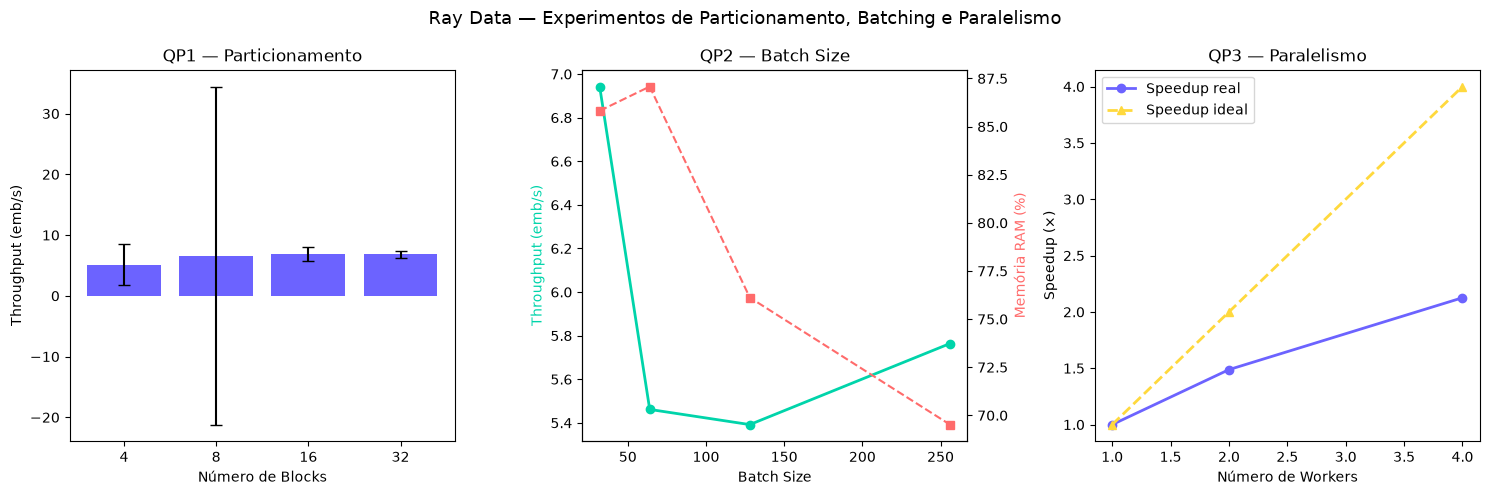

In [ ]:
import json, pandas as pd, matplotlib.pyplot as plt

def load_jsonl(path):
    return pd.DataFrame([json.loads(l) for l in open(path)])

# --- Carregar resultados ---
df1 = load_jsonl("results_exp1.jsonl")
df2 = load_jsonl("results_exp2.jsonl")
df3 = load_jsonl("results_exp3.jsonl")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Ray Data — Experimentos de Particionamento, Batching e Paralelismo", fontsize=13)

# --- Gráfico 1: Particionamento ---
ax = axes[0]
ax.bar(df1["n_blocks"].astype(str), df1["throughput_emb_s"], color="#6c63ff")
# Propaga o erro de tempo para erro de throughput
std_throughput = (2000 / df1["mean_time_s"]**2) * df1["std_time_s"]
ax.bar(df1["n_blocks"].astype(str), df1["throughput_emb_s"], color="#6c63ff")
ax.errorbar(df1["n_blocks"].astype(str), df1["throughput_emb_s"],
            yerr=std_throughput, fmt="none", color="black", capsize=4)
ax.set_xlabel("Número de Blocks"); ax.set_ylabel("Throughput (emb/s)")
ax.set_title("QP1 — Particionamento")

# --- Gráfico 2: Batch Size ---
ax = axes[1]
ax.plot(df2["batch_size"], df2["throughput_emb_s"], marker="o", color="#00d4aa", lw=2)
ax2 = ax.twinx()
ax2.plot(df2["batch_size"], df2["mean_memory_pct"], marker="s", color="#ff6b6b", lw=1.5, ls="--")
ax2.set_ylabel("Memória RAM (%)", color="#ff6b6b")
ax.set_xlabel("Batch Size"); ax.set_ylabel("Throughput (emb/s)", color="#00d4aa")
ax.set_title("QP2 — Batch Size")

# --- Gráfico 3: Paralelismo / Speedup ---
ax = axes[2]
ax.plot(df3["n_workers"], df3["speedup"], marker="o", color="#6c63ff", lw=2, label="Speedup real")
ax.plot(df3["n_workers"], df3["ideal_speedup"], marker="^", color="#ffd93d", lw=2, ls="--", label="Speedup ideal")
ax.set_xlabel("Número de Workers"); ax.set_ylabel("Speedup (×)")
ax.set_title("QP3 — Paralelismo"); ax.legend()

plt.tight_layout()
plt.savefig("resultados_experimentos.png", dpi=150, bbox_inches="tight")
print("Gráficos salvos em: resultados_experimentos.png")
plt.show()

# Armazenamento Vetorial (Opcional — AstraDB/Cassandra)

Criar conta AstraDB gratuita

Acesse: <a>astra.datastax.com</a> e crie uma conta gratuita.

Crie um banco de dados com o provider Serverless (Vector)

Baixe o Secure Connect Bundle (arquivo .zip) na aba "Connect".

Gere um token de aplicação com papel "Database Administrator".

In [12]:
# linux
export ASTRA_DB_SECURE_BUNDLE_PATH=/caminho/para/secure-connect-bundle.zip
export ASTRA_CLIENT_ID=seu_client_id
export ASTRA_CLIENT_SECRET=seu_client_secret
export ASTRA_KEYSPACE=embeddings_ks

SyntaxError: invalid syntax (3255197384.py, line 2)

In [ ]:
import ray, os
from cassandra.cluster import Cluster
from cassandra.auth import PlainTextAuthProvider

class EmbeddingAndStore:
    def __init__(self):
        from sentence_transformers import SentenceTransformer
        self.model = SentenceTransformer("intfloat/multilingual-e5-small")
        cloud_config = {"secure_connect_bundle": os.environ["ASTRA_DB_SECURE_BUNDLE_PATH"]}
        auth = PlainTextAuthProvider(os.environ["ASTRA_CLIENT_ID"], os.environ["ASTRA_CLIENT_SECRET"])
        cluster = Cluster(cloud=cloud_config, auth_provider=auth)
        self.session = cluster.connect(os.environ["ASTRA_KEYSPACE"])
        # Criar tabela (execute uma vez antes)
        self.session.execute("""
            CREATE TABLE IF NOT EXISTS embeddings (
                id int PRIMARY KEY, text text, embedding list<float>)
        """)

    def __call__(self, batch):
        embs = self.model.encode(batch["text"].tolist(), show_progress_bar=False)
        for i, (doc_id, emb) in enumerate(zip(batch["id"], embs)):
            self.session.execute(
                "INSERT INTO embeddings (id, text, embedding) VALUES (%s, %s, %s)",
                (int(doc_id), batch["text"][i], emb.tolist()))
        batch["stored"] = [True] * len(batch["id"])
        return batch

ray.init(ignore_reinit_error=True)
ds = ray.data.read_json("dataset.jsonl").repartition(8)
ds.map_batches(EmbeddingAndStore, batch_size=64, concurrency=2, batch_format="numpy").take_all()
print("Embeddings armazenados com sucesso no AstraDB!")
ray.shutdown()